# H2: płeć i wiek a prawy swipe

## O co pytamy (po ludzku)

W aplikacji osoba **A** widzi profil osoby **B** i przesuwa go w prawo (zainteresowana) albo w lewo
(nie). H2 pyta: **czy płeć (i wiek) A oraz B wpływają na to, czy A przesunie w prawo?**
Najprostsza wersja: czy ludzie częściej przesuwają w prawo profile osób **tej samej płci** niż innej?

Chcemy odpowiedzieć jedną liczbą z przedziałem niepewności, a nie samymi procentami. Tą liczbą jest
**iloraz szans (OR)**:

| OR | znaczenie |
|---|---|
| 1 | płeć odbiorcy nic nie zmienia |
| 2 | szansa na prawy swipe jest ok. 2 razy większa, gdy odbiorca ma **tę samą** płeć co nadawca |
| 0,5 | szansa jest ok. 2 razy mniejsza przy tej samej płci |

Liczymy go **osobno dla kobiet i dla mężczyzn jako nadawców**, bo ich zachowanie wygląda inaczej.

## Status: eksploracyjny

Macierz płci (kto swipe'uje kogo) widzieliśmy w EDA, **zanim** napisaliśmy H2. Wynik oznacza więc
„zaobserwowaliśmy związek", a nie „potwierdziliśmy hipotezę".

## Jednostka i zmienna wynikowa

Jeden wiersz to jeden swipe A→B na profil. Zmienna wynikowa to `y_right` (1 = prawy, 0 = lewy).

## Decyzje zespołu zastosowane tutaj

(`docs/prompts/m1-generation-plan.md`)
- cechy osoby bierzemy z wersji profilu **z dnia swipe'a**, z flagą źródła (D7),
- konta z miastem Hyderabad wyrzucamy (D10),
- płeć `O` to osobna kategoria (D8), pasma wieku 27+ łączymy w jedno (D9),
- w analizie głównej **nie** wykluczamy kont skrajnych ani mało aktywnych (D6),
- bez progu „bliskie zeru" i bez modelu dwuetapowego (D17).

## Estymator (D18, jeszcze do potwierdzenia)

Regresja logistyczna z błędami standardowymi **klastrowanymi po nadawcy i odbiorcy**. To znaczy: ta
sama osoba występuje w wielu swipe'ach, więc przedziały liczymy tak, jakby próbką byli **ludzie**, a nie
pojedyncze swipe'y. Inaczej wynik wyglądałby na pewniejszy, niż jest.

## Prywatność

Używamy tylko `sex`, `age_band`, `city` i pól swipe'ów. Pole `bio` nie jest wczytywane ani pokazywane.
Do raportu idą tylko liczby zbiorcze (`data/README.md`).

## Skąd dane

Jeśli w `data/processed/` są pliki `users`, `swipes` i `profile_history` (parquet), notebook używa ich.
W przeciwnym razie działa na **danych syntetycznych**, w których sami ustawiliśmy efekt. Służą one tylko
do sprawdzenia, że kod działa. **Wyniki z danych syntetycznych nic nie mówią o RentFriends.**

In [1]:
# reload src/rentfriends automatically, so edits to the module apply without a kernel restart
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from rentfriends import h2
from rentfriends.synthetic import make_synthetic_tables

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

SEED = 20261102  # fixed for bootstrap, permutations and CV folds
N_BOOT = 1000  # cluster bootstrap replicates for the rate matrix
N_PERM = 1000  # permutations for the null baseline
N_FOLDS = 5

# Chart style from STYLEGUIDE.md: purple primary, blue comparison, gray for null/baseline.
PURPLE, PURPLE_INK, BLUE, GRAY, HAIR = "#A247E3", "#8B34C4", "#234CE0", "#595959", "#D5D2CB"

DATA_DIR = Path("../data/processed")
REQUIRED = ["users", "swipes", "profile_history"]

## 1. Wczytanie danych

In [2]:
USE_REAL = all((DATA_DIR / f"{t}.parquet").exists() for t in REQUIRED)
if USE_REAL:
    tables = h2.load_tables(DATA_DIR)
    truth = None
    print("PRAWDZIWE DANE z", DATA_DIR.resolve())
else:
    tables, truth = make_synthetic_tables(n_users=1500, swipes_per_user=60, seed=SEED % 1000)
    print("!" * 70)
    print("DANE SYNTETYCZNE: nie znaleziono prawdziwych danych.")
    print("Liczby poniżej tylko testują kod i nic nie mówią o RentFriends.")
    print("Prawdziwy log(OR) ustawiony w generatorze, według płci nadawcy:", truth)
    print("!" * 70)

print(
    f"użytkownicy: {len(tables.users)}, swipe'y: {len(tables.swipes)}, "
    f"wersje profili: {len(tables.profile_history)}"
)

PRAWDZIWE DANE z /home/michal-jankowski/pwr/digital-media-analysis/data/processed
użytkownicy: 2065, swipe'y: 116414, wersje profili: 4508


## 2. Tabela do analizy i filtry

**Co tu się dzieje:** z surowych swipe'ów zostawiamy tylko swipe'y na profile (bez swipe'ów na ogłoszenia
mieszkań i bez swipe'ów na samego siebie), wyrzucamy konta z Hyderabadu i każdemu swipe'owi
przypisujemy płeć i wiek nadawcy oraz odbiorcy **z dnia swipe'a**.

Poniższy lejek pokazuje, ile swipe'ów tracimy na każdym kroku (G6, G7, G10).

In [3]:
df = h2.build_swipe_table(tables)  # main: as-of features (D7), no Hyderabad (D10)

raw = tables.swipes
profile = raw[(raw["target_type"] == "profile") & raw["target_user_key"].notna()]
profile = profile[profile["user_key"] != profile["target_user_key"]]
funnel = pd.Series(
    {
        "wszystkie swipe'y": len(raw),
        "swipe'y na profile (bez swipe'ów na siebie)": len(profile),
        "po wyrzuceniu Hyderabadu (D10)": len(df),
        "znana płeć obu stron": int(df["same_sex"].notna().sum()),
        "...i znane pasmo wieku obu stron": int(df["same_band"].notna().sum()),
    },
    name="swipe'y",
)
display(funnel.to_frame())

print(
    f"nadawcy: {df['sender'].nunique()}, odbiorcy: {df['receiver'].nunique()}, "
    f"ogólny odsetek prawych swipe'ów = {df['y_right'].mean():.3f}"
)
print()
print("Skąd pochodzi wersja profilu (D7, na poziomie pary):")
display(df["asof_source"].value_counts(normalize=True).to_frame("udział"))
print(
    f"Konta skrajne (same prawe albo same lewe, >= {h2.MIN_SWIPES_ACTIVE} swipe'ów) "
    f"zostają w analizie głównej (D6): {df.loc[df['sender_extreme'], 'sender'].nunique()} kont, "
    f"{int(df['sender_extreme'].sum())} swipe'ów"
)

,swipe'y
wszystkie swipe'y,116414
swipe'y na profile (bez swipe'ów na siebie),95144
po wyrzuceniu Hyderabadu (D10),94295
znana płeć obu stron,94295
...i znane pasmo wieku obu stron,93717


nadawcy: 1544, odbiorcy: 1363, ogólny odsetek prawych swipe'ów = 0.205

Skąd pochodzi wersja profilu (D7, na poziomie pary):


,udział
asof_source,
prior_version,0.503
first_version,0.489
users_current,0.008


Konta skrajne (same prawe albo same lewe, >= 10 swipe'ów) zostają w analizie głównej (D6): 347 kont, 15968 swipe'ów


## 3. Macierz: jaki odsetek swipe'ów jest prawy, według płci nadawcy i odbiorcy

**Jak czytać:** wiersz to płeć nadawcy, kolumna to płeć odbiorcy. Komórka `F → M` to odsetek prawych
swipe'ów, które **kobiety** dały **mężczyznom**. Jeśli ludzie wolą swoją płeć, przekątna (`F → F`,
`M → M`) będzie ciemniejsza niż reszta.

Przedziały ufności w tabeli (`ci`) liczymy przez **bootstrap po nadawcach**: losujemy całych ludzi, a nie
pojedyncze swipe'y. Są szersze niż przedział Wilsona z EDA, który zakładał, że każdy swipe jest niezależny.

Płeć `O` jest rzadka i najczęściej powstaje przez zmianę płci w profilu (G16), więc te komórki czytamy
ostrożnie. Tę macierz widzieliśmy przed H2, dlatego jest eksploracyjna.

,n swipe'ów,n prawych,odsetek prawych,przedział (bootstrap),Wilson dół,Wilson góra
komórka (nadawca -> odbiorca),,,,,,
F -> F,32101,6435,0.200,"[0.174, 0.230]",0.196,0.205
F -> M,17242,1469,0.085,"[0.062, 0.111]",0.081,0.089
F -> O,958,107,0.112,"[0.085, 0.141]",0.093,0.133
M -> F,24857,7358,0.296,"[0.248, 0.345]",0.290,0.302
M -> M,17398,3467,0.199,"[0.162, 0.240]",0.193,0.205
M -> O,840,157,0.187,"[0.145, 0.231]",0.162,0.215
O -> F,533,210,0.394,"[0.214, 0.581]",0.353,0.436
O -> M,345,151,0.438,"[0.134, 0.659]",0.386,0.490
O -> O,21,9,0.429,"[0.118, 0.731]",0.245,0.635


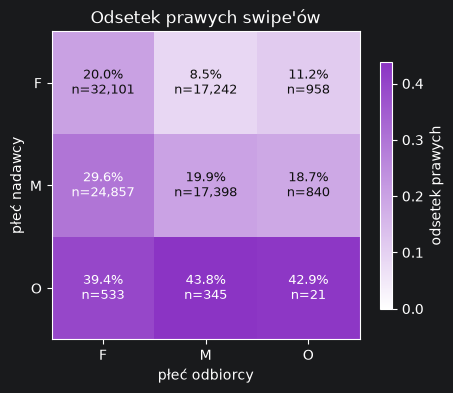

In [4]:
matrix = h2.rate_matrix(df, n_boot=N_BOOT, seed=SEED)
tbl = matrix.assign(
    cell=lambda t: t["sender_sex"] + " -> " + t["receiver_sex"],
    ci=lambda t: t.apply(
        lambda r: "" if pd.isna(r["rate"]) else f"[{r['ci_low']:.3f}, {r['ci_high']:.3f}]", axis=1
    ),
)[["cell", "n", "k", "rate", "ci", "wilson_low", "wilson_high"]]
tbl.columns = [
    "komórka (nadawca -> odbiorca)",
    "n swipe'ów",
    "n prawych",
    "odsetek prawych",
    "przedział (bootstrap)",
    "Wilson dół",
    "Wilson góra",
]
display(tbl.set_index("komórka (nadawca -> odbiorca)"))

rates = matrix.pivot(index="sender_sex", columns="receiver_sex", values="rate").loc[
    h2.SEXES, h2.SEXES
]
ns = matrix.pivot(index="sender_sex", columns="receiver_sex", values="n").loc[h2.SEXES, h2.SEXES]
cmap = LinearSegmentedColormap.from_list("one_hue", ["#FFFFFF", PURPLE_INK])
fig, ax = plt.subplots(figsize=(5.2, 4))
vmax = max(0.35, np.nanmax(rates.to_numpy(dtype=float)))
im = ax.imshow(rates.to_numpy(dtype=float), cmap=cmap, vmin=0, vmax=vmax)
ax.grid(False)
ax.set_xticks(range(3), h2.SEXES)
ax.set_yticks(range(3), h2.SEXES)
ax.set_xlabel("płeć odbiorcy")
ax.set_ylabel("płeć nadawcy")
for i in range(3):
    for j in range(3):
        r = rates.iat[i, j]
        if pd.isna(r):
            continue
        dark = r > 0.6 * im.get_clim()[1]
        ax.text(
            j,
            i,
            f"{r:.1%}\nn={int(ns.iat[i, j]):,}",
            ha="center",
            va="center",
            color="white" if dark else "#0F0F0F",
            fontsize=9,
        )
ax.set_title("Odsetek prawych swipe'ów")
fig.colorbar(im, ax=ax, label="odsetek prawych", shrink=0.8)
plt.show()

## 4. Główny wynik: iloraz szans, ta sama vs inna płeć, według płci nadawcy

**To jest sedno H2.** Dla każdej płci nadawcy liczymy jedną liczbę, OR, która mówi, ile razy większa jest
szansa na prawy swipe, gdy odbiorca ma **tę samą** płeć co nadawca, niż gdy ma inną.

- **OR > 1:** ludzie częściej swipe'ują w prawo swoją płeć,
- **OR = 1:** płeć odbiorcy nic nie zmienia (przerywana linia na wykresie),
- **OR < 1:** częściej swipe'ują w prawo inną płeć.

**Jak oceniać wykres:** kropka to oszacowanie, a odcinek to przedział ufności 95%. Jeśli odcinek **nie
dotyka** linii OR = 1, mamy związek. Szeroki odcinek oznacza małą pewność (zwykle mało swipe'ów).

Dwa modele:
- **surowy:** tylko płeć nadawcy i „ta sama płeć" (to jest wielkość z D17),
- **z kontrolami:** dodatkowo różnica pasm wieku, to samo pasmo i relacja miast (to samo / inne /
  nieznane). OR mówi wtedy: ile zostaje z efektu, gdy porównujemy pary podobne pod względem wieku i miasta.

**Uwaga o interpretacji liczby.** To OR *uśredniony po populacji*. Hojni nadawcy i popularni odbiorcy
wprowadzają szum, który ściąga zwykłą regresję w stronę 1. Model z efektami losowymi nadawcy i odbiorcy
dałby **większe** OR. Dlatego porównujemy OR tylko między wynikami z tego samego estymatora.

,z kontrolami,płeć nadawcy,n swipe'ów,n nadawców,P(prawy | ta sama płeć),P(prawy | inna płeć),OR,OR dół 95%,OR góra 95%,p
0,False,F,50301,871,0.200,0.087,2.645,2.063,3.390,0.000
1,False,M,43095,664,0.199,0.292,0.602,0.498,0.729,0.000
2,False,O,899,30,0.429,0.411,1.074,0.490,2.355,0.858
3,True,F,50241,871,0.201,0.087,2.439,1.909,3.116,0.000
4,True,M,42621,659,0.201,0.295,0.657,0.541,0.799,0.000
5,True,O,855,28,0.450,0.414,1.143,0.473,2.759,0.767


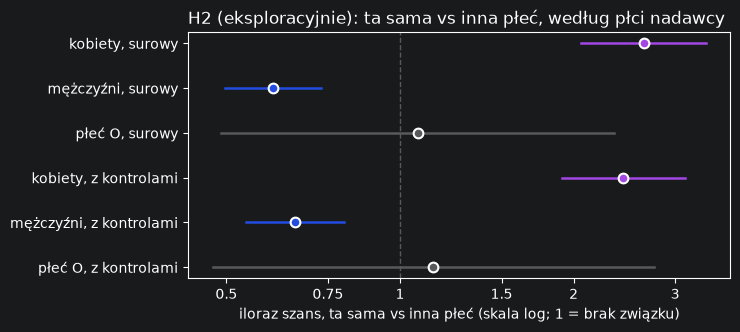

Uwaga: nadawcy ['O'] mają < 1000 swipe'ów, przedział jest bardzo szeroki.


In [5]:
crude = h2.or_by_sender_sex(df)
adjusted = h2.or_by_sender_sex(df, controls=True)
main_res = pd.concat([crude, adjusted], ignore_index=True)
shown = main_res[
    [
        "controls",
        "sender_sex",
        "n",
        "n_senders",
        "p_right_same",
        "p_right_diff",
        "odds_ratio",
        "ci_low",
        "ci_high",
        "p_value",
    ]
].copy()
shown.columns = [
    "z kontrolami",
    "płeć nadawcy",
    "n swipe'ów",
    "n nadawców",
    "P(prawy | ta sama płeć)",
    "P(prawy | inna płeć)",
    "OR",
    "OR dół 95%",
    "OR góra 95%",
    "p",
]
display(shown)


def forest(res, ax, title):
    """Dot + CI per row on a log axis, reference line at OR = 1."""
    labels = []
    colors = {"F": PURPLE, "M": BLUE, "O": GRAY}
    for y, (_, r) in enumerate(res.iterrows()):
        ax.plot([r["ci_low"], r["ci_high"]], [y, y], color=colors[r["sender_sex"]], lw=1.8)
        ax.plot(r["odds_ratio"], y, "o", color=colors[r["sender_sex"]], ms=7, mec="white", mew=1.5)
        labels.append(r["label"])
    ax.axvline(1, color=GRAY, ls="--", lw=1)
    ax.set_xscale("log")
    lo, hi = ax.get_xlim()
    ticks = [t for t in (0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6) if lo <= t <= hi]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.minorticks_off()
    ax.set_yticks(range(len(labels)), labels)
    ax.invert_yaxis()
    ax.set_xlabel("iloraz szans, ta sama vs inna płeć (skala log; 1 = brak związku)")
    ax.set_title(title, loc="left")


SEX_PL = {"F": "kobiety", "M": "mężczyźni", "O": "płeć O"}
plot = main_res.assign(
    label=lambda t: (
        t["sender_sex"].map(SEX_PL) + ", " + np.where(t["controls"], "z kontrolami", "surowy")
    )
)
plot = plot.sort_values(["controls", "sender_sex"])
fig, ax = plt.subplots(figsize=(7, 3.2))
forest(plot, ax, "H2 (eksploracyjnie): ta sama vs inna płeć, według płci nadawcy")
plt.show()
small = plot.loc[plot["n"] < 1000, "sender_sex"].unique()
if len(small):
    print(f"Uwaga: nadawcy {list(small)} mają < 1000 swipe'ów, przedział jest bardzo szeroki.")

### Test na przypadek: tasowanie płci odbiorców

**Pytanie:** czy tak duże OR mogłoby wyjść samo z siebie, przez przypadek?

**Jak sprawdzamy:** losowo mieszamy płeć między **odbiorcami** (całymi ludźmi, każdy zachowuje swoje
swipe'y i swoją popularność). To usuwa jakikolwiek związek płci odbiorcy z wynikiem, a wszystko inne
zostaje. Robimy to 1000 razy i patrzymy, jak duże `log(OR)` wychodzi wtedy z samego przypadku
(szare słupki).

**Jak czytać:** kolorowa pionowa linia to nasz prawdziwy wynik. Jeśli leży daleko od szarego
rozkładu, efekt nie jest przypadkiem. Jeśli leży w jego środku, mamy wynik negatywny (to też pełnoprawny
wynik). `p_perm` to odsetek tasowań, które dały wynik co najmniej tak skrajny jak nasz. Wynik `log(OR) = 0`
oznacza brak związku.

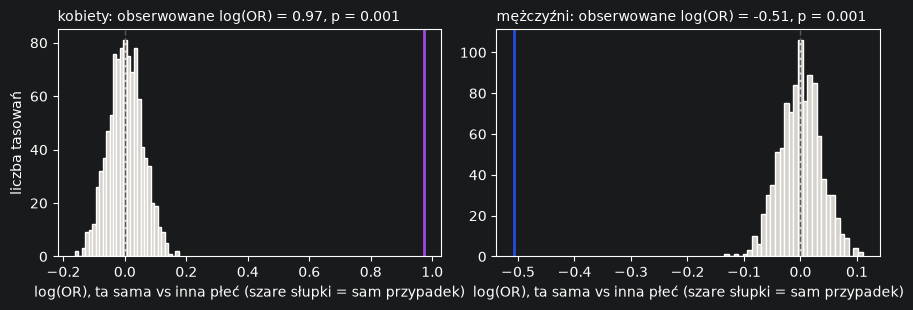

,obserwowane log(OR),"przypadek 2,5%","przypadek 97,5%",p_perm
płeć nadawcy,,,,
F,0.972,-0.103,0.109,0.001
M,-0.507,-0.066,0.070,0.001


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=False)
perm_rows = []
for ax, g, col in zip(axes, ["F", "M"], [PURPLE, BLUE], strict=True):
    obs, null = h2.permutation_null_or(df, g, n_perm=N_PERM, seed=SEED)
    p = (np.sum(np.abs(null) >= abs(obs)) + 1) / (len(null) + 1)
    lo, hi = np.quantile(null, [0.025, 0.975])
    perm_rows.append(
        {
            "płeć nadawcy": g,
            "obserwowane log(OR)": obs,
            "przypadek 2,5%": lo,
            "przypadek 97,5%": hi,
            "p_perm": p,
        }
    )
    ax.hist(null, bins=30, color=HAIR, edgecolor="white")
    ax.axvline(obs, color=col, lw=2)
    ax.axvline(0, color=GRAY, ls="--", lw=1)
    ax.set_title(
        f"{SEX_PL[g]}: obserwowane log(OR) = {obs:.2f}, p = {p:.3f}", loc="left", fontsize=10
    )
    ax.set_xlabel("log(OR), ta sama vs inna płeć (szare słupki = sam przypadek)")
axes[0].set_ylabel("liczba tasowań")
plt.tight_layout()
plt.show()
display(pd.DataFrame(perm_rows).set_index("płeć nadawcy"))

## 5. Analizy wrażliwości: czy wynik zależy od naszych decyzji?

**Pytanie:** czy wniosek zmienia się, gdy dane przygotujemy trochę inaczej? Każdy wiersz liczy surowe OR
na innej wersji danych:

- **main:** nasza analiza główna,
- **current profile:** płeć i wiek z dzisiejszego profilu, a nie z dnia swipe'a,
- **only prior_version:** tylko swipe'y, dla których znamy wcześniejszą wersję profilu,
- **with Hyderabad:** z kontami z Hyderabadu,
- **without extreme senders:** bez kont, które swipe'ują tylko w prawo albo tylko w lewo (boty),
- **senders >= 10 swipes:** tylko nadawcy, którzy dali co najmniej 10 swipe'ów.

**Jak czytać:** jeśli wszystkie kropki leżą blisko siebie, wynik jest odporny na te decyzje. Jeśli któraś
mocno odstaje, trzeba o tym napisać w raporcie. Wszystkie OR pochodzą z tego samego estymatora, więc
można je porównywać.

swipe'y w wariancie  swipe'y tej płci    OR  OR dół 95%  OR góra 95%
wariant                       płeć nadawcy                                                                      
main (as-of, no Hyderabad)    F                           94295             50301 2.645       2.063        3.390
                              M                           94295             43095 0.602       0.498        0.729
                              O                           94295               899 1.074       0.490        2.355
current profile (users table) F                           94295             48765 2.514       1.968        3.212
                              M                           94295             41838 0.603       0.496        0.733
                              O                           94295              3692 1.017       0.733        1.410
only prior_version swipes     F                           47465             24791 2.280       1.684        3.087
                              M                           47465             22121 0.524       0.402        0.681
                              O                           47465               553 1.446       0.518        4.036
with Hyderabad                F                           95144             50313 2.641       2.062        3.384
                              M                           95144             43932 0.598       0.495        0.722
                              O                           95144               899 1.074       0.490        2.355
without extreme senders (G10) F                           78327             41977 2.839       2.184        3.692
                              M                           78327             35597 0.559       0.454        0.687
                              O                           78327               753 1.036       0.420        2.556
senders with >= 10 swipes     F                           92587             49325 2.643       2.053        3.402
                              M                           92587             42387 0.598       0.493        0.725
                              O                           92587               875 1.421       0.698        2.892

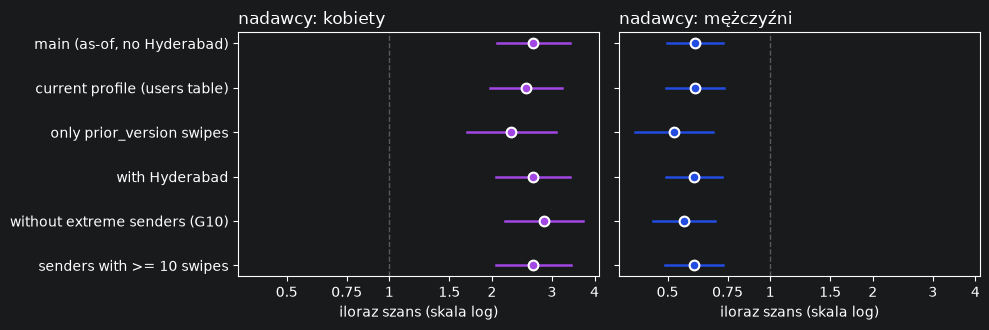

In [7]:
scenarios = {
    "main (as-of, no Hyderabad)": df,
    "current profile (users table)": h2.build_swipe_table(tables, feature_version="users"),
    "only prior_version swipes": df[df["asof_source"] == "prior_version"],
    "with Hyderabad": h2.build_swipe_table(tables, drop_hyderabad=False),
    "without extreme senders (G10)": df[~df["sender_extreme"]],
    f"senders with >= {h2.MIN_SWIPES_ACTIVE} swipes": df[df["sender_n"] >= h2.MIN_SWIPES_ACTIVE],
}
sens = []
for name, d in scenarios.items():
    r = h2.or_by_sender_sex(d)
    r.insert(0, "scenario", name)
    r.insert(1, "scenario_swipes", len(d))
    sens.append(r)
sens = pd.concat(sens, ignore_index=True)
sens_shown = sens[
    ["scenario", "sender_sex", "scenario_swipes", "n", "odds_ratio", "ci_low", "ci_high"]
].copy()
sens_shown.columns = [
    "wariant",
    "płeć nadawcy",
    "swipe'y w wariancie",
    "swipe'y tej płci",
    "OR",
    "OR dół 95%",
    "OR góra 95%",
]
display(sens_shown.set_index(["wariant", "płeć nadawcy"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for ax, g in zip(axes, ["F", "M"], strict=True):
    part = sens[sens["sender_sex"] == g].assign(label=lambda t: t["scenario"])
    forest(part, ax, f"nadawcy: {SEX_PL[g]}")
    ax.set_xlabel("iloraz szans (skala log)")
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

## 6. Czy cechy demograficzne pomagają przewidywać swipe'y u nowych osób?

**Pytanie:** gdybyśmy znali tylko płeć i wiek nadawcy i odbiorcy, czy lepiej przewidzielibyśmy prawy swipe
u ludzi, których model **nie widział** podczas uczenia?

**Jak sprawdzamy:** dzielimy nadawców na 5 grup. Uczymy model na 4 grupach i testujemy na piątej, i tak
5 razy. Porównujemy trzy modele:
- `null`: zgaduje tylko ogólny odsetek prawych swipe'ów,
- `sex`: zna płeć nadawcy i odbiorcy,
- `sex+age`: dodatkowo zna różnicę pasm wieku i to, czy to samo pasmo.

**Jak czytać:** `log loss` to błąd przewidywań (mniejszy = lepiej). Wartość ujemna w tabeli oznacza, że
większy model przewiduje lepiej. Jeśli zmiana jest mała w porównaniu z rozrzutem między foldami, nie ma
realnej poprawy. `AUC` = 0,5 oznacza zgadywanie, a 1 oznacza idealne przewidywanie.

To sprawdzenie, czy w danych jest sygnał, a nie wyścig o wynik modelu (zasada kursu). Ten sam odbiorca może
trafić zarówno do uczenia, jak i do testu, więc kontrolujemy przeciek tylko po stronie nadawców.

In [8]:
cv = h2.grouped_cv(df, n_splits=N_FOLDS, seed=SEED)
wide = cv.pivot(index="fold", columns="block", values="logloss")[["null", "sex", "sex+age"]]
delta = pd.DataFrame(
    {
        "sex vs null": wide["sex"] - wide["null"],
        "sex+age vs null": wide["sex+age"] - wide["null"],
        "sex+age vs sex": wide["sex+age"] - wide["sex"],
    }
)
print("Zmiana log loss w każdym foldzie (ujemna = większy model przewiduje lepiej):")
display(delta)
summary = pd.DataFrame({"średnia": delta.mean(), "odch. std. między foldami": delta.std(ddof=1)})
display(summary)
print("Średnie AUC według modelu:")
display(cv.groupby("block")["auc"].mean().loc[["null", "sex", "sex+age"]].to_frame("auc"))

Zmiana log loss w każdym foldzie (ujemna = większy model przewiduje lepiej):


,sex vs null,sex+age vs null,sex+age vs sex
fold,,,
0,-0.003,-0.005,-0.003
1,-0.027,-0.034,-0.007
2,-0.029,-0.037,-0.008
3,-0.002,0.000,0.002
4,-0.017,-0.018,-0.001


,średnia,odch. std. między foldami
sex vs null,-0.016,0.013
sex+age vs null,-0.019,0.017
sex+age vs sex,-0.003,0.004


Średnie AUC według modelu:


,auc
block,
null,0.500
sex,0.603
sex+age,0.620


## 7. Wniosek

### Wniosek (eksploracyjny)

**Płeć nadawcy i odbiorcy wyraźnie wiąże się z prawym swipe'em, ale wzór jest asymetryczny i nie jest
prostą preferencją „swojej płci".**

| Nadawca | P(prawy), ta sama płeć | P(prawy), inna płeć | OR surowy [95% CI] | OR z kontrolami [95% CI] |
|---|---|---|---|---|
| kobiety (871 nadawców) | 20,0% | 8,7% | 2,65 [2,06; 3,39] | 2,44 [1,91; 3,12] |
| mężczyźni (664 nadawców) | 19,9% | 29,2% | 0,60 [0,50; 0,73] | 0,66 [0,54; 0,80] |
| płeć O (30 nadawców) | 42,9% | 41,1% | 1,07 [0,49; 2,36] | 1,14 [0,47; 2,76] |

- **Kobiety** częściej swipe'ują w prawo kobiety niż mężczyzn. Szansa jest ok. 2,6 razy większa.
- **Mężczyźni** częściej swipe'ują w prawo kobiety niż mężczyzn. Dla nich „ta sama płeć" oznacza profil
  mężczyzny, dlatego OR jest poniżej 1 (szansa ok. 0,6 razy).
- **Profile kobiet dostają więcej prawych swipe'ów niż profile mężczyzn od obu grup nadawców** (macierz z
  sekcji 3). Dlatego „ta sama vs inna płeć" miesza tu dwie rzeczy: preferencję względem własnej płci
  i ogólną różnicę w tym, jak często prawy swipe dostają profile kobiet i mężczyzn. Z tych danych nie umiemy
  ich rozdzielić ani wskazać powodu (np. poczucie bezpieczeństwa, orientacja, inne).
- **To nie jest twarda bramka.** Kobiety dały mężczyznom 1 469 prawych swipe'ów na 17 242 (8,5%), czyli
  daleko od zera. Zgodnie z D17 nie wyznaczamy progu „bliskie zeru", opisujemy tylko wielkość efektu.
- **Płeć O: brak wniosku.** 30 nadawców i 899 swipe'ów, przedziały obejmują 1 we wszystkich wariantach.
  Odsetki prawych swipe'ów w tych komórkach są wysokie (ok. 40%), ale komórki są małe.
- **Kontrole nie zmieniają obrazu.** Wiek i miasto zmieniają OR tylko nieznacznie (F 2,65 → 2,44, M 0,60 → 0,66).

### Test na przypadek

Tasowanie płci odbiorców: obserwowane `log(OR)` wynosi 0,97 (kobiety) i −0,51 (mężczyźni), a przedział
przypadku to ok. ±0,1. `p_perm` = 0,001 to najmniejsza wartość możliwa przy 1000 tasowań (czyli p < 0,001).
Wyniku nie tłumaczy przypadek.

### Odporność (sekcja 5)

- OR dla kobiet wynosi 2,3 do 2,8, a dla mężczyzn 0,52 do 0,60 we wszystkich 6 wariantach. Przedział
  nigdy nie obejmuje 1.
- Najsilniej wychodzi bez kont skrajnych (kobiety 2,84, mężczyźni 0,56). Konta skrajne to 347 kont i
  15 968 swipe'ów (17% wszystkich), więc rozcieńczają efekt.
- Wersja profilu z dnia swipe'a i bieżący profil dają prawie to samo (kobiety 2,65 vs 2,51).
- Dla płci O wynik jest niestabilny (OR 1,0 do 1,45), przedział zawsze obejmuje 1.

### Poza próbą (sekcja 6)

Dodanie płci poprawia log loss średnio o 0,016, ale rozrzut między foldami jest duży (od −0,002 do −0,029).
AUC wynosi 0,60, a z wiekiem 0,62. Demografia niesie realny, ale umiarkowany sygnał i nie wystarcza do
dobrego przewidywania. Wiek dodaje tylko −0,003 log loss (rozrzut 0,004) i w jednym foldzie pogarsza wynik,
więc jego wkład mieści się w szumie.

### Czego nie oszacowaliśmy

**Wielkości efektu wieku.** H2 mówi o płci i wieku, ale notebook policzył OR tylko dla płci. Wiek występuje
jako kontrola i w walidacji poza próbą, bez własnego oszacowania z przedziałem ufności. Wniosek o wieku
byłby więc nadmierny.

### Ograniczenia (z karty M1)

- Eksploracyjnie: macierz płci widzieliśmy przed sformułowaniem H2 (D17).
- Ekspozycja: widzimy tylko pary pokazane przez feed. Jeśli aplikacja filtruje płeć, wymusza `same_sex`
  bez żadnej zmienności (G1). Wynik opisuje zachowanie w aplikacji, nie preferencje ogółu.
- Płeć `O` jest mała i najczęściej powstaje przez zmianę płci (G8, G16), więc nie interpretujemy jej mocno.
- Wiek znamy tylko jako pasmo i dominuje 18-20 (G13). Próba jest jednorodna (G6).
- OR uśredniony po populacji, a nie warunkowy na nadawcę i odbiorcę (sekcja 4). Model z efektami losowymi
  dałby OR dalsze od 1. Estymator nie jest ostateczny (D18).
- Prawy swipe to nie decyzja o wspólnym wynajmie (G9). Korelacja, nie przyczynowość.
- Mamy tylko dzień, bez godzin (G3).